# 02 - Task 2: encoder-decoder LSTM with attention

Forecast the temperature in Hanoi for the next five hours (t+1 ... t+5) from the last 24 hours of weather (notebook 01).

Three sequence-to-sequence models are trained with exactly the same data, layers and training settings. They differ only in how the decoder uses the encoder:

| Run | Attention | What the decoder sees |
|---|---|---|
| `seq2seq_lstm` | none | only the last encoder state (one fixed context vector, Chapter 8) |
| `seq2seq_lstm_dot_attention` | dot-product (Luong), `keras.layers.Attention` | all 24 encoder states, weighted by the score `s_t · h_i` |
| `seq2seq_lstm_additive_attention` | additive (Bahdanau-style score), `keras.layers.AdditiveAttention` | all 24 encoder states, weighted by a score learned by a small feed-forward network |

Settings are compared on the validation set only. The test set is used once, in notebook 03.

In [1]:
import os, sys
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
sys.path.insert(0, os.path.abspath(".."))

import keras
from keras import layers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import FIGURES_DIR, HORIZON, N_STEPS, SEED
from src.metrics import multistep_metrics
from src.training import load_history, load_trained, log_experiment, plot_history, train_model
from src.weather_data import inverse_target, prepare_forecast_data

FIG_DIR = FIGURES_DIR / "forecast" / "learning_curves"
FIG_DIR.mkdir(parents=True, exist_ok=True)
%matplotlib inline

In [2]:
UNITS = 64          # số nơ-ron của LSTM encoder và LSTM decoder
BATCH_SIZE = 128
EPOCHS = 40         # số epoch tối đa, EarlyStopping có thể dừng sớm hơn
LEARNING_RATE = 1e-3
RUNS = {"seq2seq_lstm": None,
        "seq2seq_lstm_dot_attention": "dot",
        "seq2seq_lstm_additive_attention": "additive"}

# True: train lại cả 3 model từ đầu (khoảng 1 giờ trên CPU); False: load model và lịch sử train đã lưu
TRAIN = False

## 1. Data

`prepare_forecast_data()` (in `src/weather_data.py`) repeats the steps of notebook 01: chronological 70/15/15 split, `MinMaxScaler` fitted on the training period, then sliding windows of 24 hours -> 5 hours inside each part. The model learns on the scaled values; predictions are converted back to °C before computing the metrics.

In [3]:
data = prepare_forecast_data(N_STEPS, HORIZON)
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
sc, ti = data["scaler"], data["target_idx"]
print("train:", X_train.shape, y_train.shape, "| val:", X_val.shape, y_val.shape)

train: (61342, 24, 9) (61342, 5) | val: (13123, 24, 9) (13123, 5)


## 2. Model

All three models follow the encoder-decoder structure of Chapter 8 and the lecturer's `DL_Encoder` notebook (encoder -> `RepeatVector` -> decoder -> `TimeDistributed(Dense)`), with LSTM cells instead of `SimpleRNN`:

1. **Encoder:** an LSTM reads the 24 hours and returns its hidden state at every hour (`return_sequences=True`, these are the h_1 ... h_24 of the attention slides) and its final states h, c.
2. **Decoder:** the final encoder state is repeated 5 times (`RepeatVector`), one copy per forecast hour, and a second LSTM starts from the encoder's final states (`initial_state=[h, c]`, as on the Seq2Seq slide where the decoder state is initialised from the encoder). It returns one state s_t for each of the 5 hours.
3. **Attention** (models 2 and 3): for each forecast hour the decoder state s_t is the query and the 24 encoder states are the keys and values (Chapter 9). The scores are turned into weights with softmax (they sum to 1 over the 24 hours) and the context vector c_t is the weighted sum of the encoder states. `[s_t ; c_t]` is passed on. The attention is computed after the decoder step, as in Luong et al.; model 2 uses the dot score, model 3 the additive score.
4. **Output:** a `Dense(32, relu)` and a `Dense(1)` applied to every forecast hour (`TimeDistributed`) give the 5 temperatures.

Loss: mean squared error on the scaled temperature; optimizer Adam (learning rate 1e-3).

In [4]:
def build_seq2seq(attention=None, units=UNITS, n_steps=N_STEPS, n_features=X_train.shape[2], horizon=HORIZON):
    inputs = keras.Input(shape=(n_steps, n_features), name="input_window")

    # Encoder: trả về trạng thái ẩn ở cả 24 giờ (dùng cho attention) và trạng thái cuối (h, c)
    enc_seq, state_h, state_c = layers.LSTM(units, return_sequences=True, return_state=True, name="encoder_lstm")(inputs)

    # Decoder: lặp lại trạng thái cuối của encoder cho 5 giờ cần dự báo, khởi tạo decoder bằng (h, c) của encoder
    dec_in = layers.RepeatVector(horizon, name="repeat_context")(state_h)
    dec_seq = layers.LSTM(units, return_sequences=True, name="decoder_lstm")(dec_in, initial_state=[state_h, state_c])

    x = dec_seq
    if attention is not None:
        # query = trạng thái decoder s_t, key = value = 24 trạng thái encoder h_i
        if attention == "dot":
            context = layers.Attention(name="attention")([dec_seq, enc_seq])          # score = s_t . h_i
        else:
            context = layers.AdditiveAttention(name="attention")([dec_seq, enc_seq])  # score = v . tanh(s_t + h_i)
        x = layers.Concatenate(name="concat_state_context")([dec_seq, context])

    x = layers.TimeDistributed(layers.Dense(32, activation="relu"), name="dense_hidden")(x)
    x = layers.TimeDistributed(layers.Dense(1), name="dense_output")(x)
    outputs = layers.Reshape((horizon,), name="forecast")(x)

    name = "seq2seq_lstm" + ("" if attention is None else f"_{attention}_attention")
    model = keras.Model(inputs, outputs, name=name)
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss="mse", metrics=["mae"])
    return model


build_seq2seq("dot").summary()

Model: "seq2seq_lstm_dot_attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_window        │ (None, 24, 9)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 24, 64),  │     18,944 │ input_window[0][… │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_context      │ (None, 5, 64)     │          0 │ encoder_lstm[0][… │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ (None, 5, 64)     │     33,024 │ repeat_context[0… │
│                     │                   │            │ encoder_lstm[0][… │
│                     │                   │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 5, 64)     │          0 │ decoder_lstm[0][… │
│ (Attention)         │                   │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat_state_conte… │ (None, 5, 128)    │          0 │ decoder_lstm[0][… │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_hidden        │ (None, 5, 32)     │      4,128 │ concat_state_con… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_output        │ (None, 5, 1)      │         33 │ dense_hidden[0][… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast (Reshape)  │ (None, 5)         │          0 │ dense_output[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 56,129 (219.25 KB)

 Trainable params: 56,129 (219.25 KB)

 Non-trainable params: 0 (0.00 B)

Attention adds only 2,048 trainable parameters (the `Dense` after the concatenation gets 64 more inputs); the dot-product layer itself has no weights and the additive layer has 64 (its scale vector v). So any difference between the models comes from how the information is used, not from model size.

## 3. Training

- `ModelCheckpoint` saves the epoch with the lowest validation loss,
- `EarlyStopping` stops after 8 epochs without a better validation loss and restores the best weights,
- `ReduceLROnPlateau` halves the learning rate after 3 epochs without improvement.

The training windows are shuffled by `fit` (each window already contains its own 24 hours in order, and the split itself is by time, so this does not leak future data).

In [5]:
histories = {}
for run, attention in RUNS.items():
    if TRAIN:
        keras.utils.set_random_seed(SEED)
        model = build_seq2seq(attention)
        history, minutes = train_model(model, run, X_train, y_train, (X_val, y_val), EPOCHS, BATCH_SIZE)
        best = int(history["val_loss"].idxmin())
        log_experiment({"run": run, "task": "task2_forecast", "attention": attention or "none", "units": UNITS,
                        "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE, "max_epochs": EPOCHS,
                        "epochs_trained": len(history), "best_epoch": best + 1,
                        "best_val_loss": round(history["val_loss"].min(), 6),
                        "train_minutes": round(minutes, 1), "params": model.count_params()})
    histories[run] = load_history(run)

Epoch 1/40
480/480 - 37s - 77ms/step - loss: 0.0048 - mae: 0.0464 - val_loss: 0.0016 - val_mae: 0.0307 - learning_rate: 1.0000e-03
Epoch 2/40
480/480 - 20s - 42ms/step - loss: 0.0012 - mae: 0.0265 - val_loss: 0.0013 - val_mae: 0.0269 - learning_rate: 1.0000e-03
Epoch 3/40
480/480 - 25s - 51ms/step - loss: 9.9340e-04 - mae: 0.0233 - val_loss: 0.0014 - val_mae: 0.0284 - learning_rate: 1.0000e-03
Epoch 4/40
480/480 - 25s - 52ms/step - loss: 8.6783e-04 - mae: 0.0215 - val_loss: 0.0014 - val_mae: 0.0281 - learning_rate: 1.0000e-03
Epoch 5/40

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
480/480 - 25s - 53ms/step - loss: 8.0687e-04 - mae: 0.0206 - val_loss: 0.0012 - val_mae: 0.0257 - learning_rate: 1.0000e-03
Epoch 6/40
480/480 - 25s - 51ms/step - loss: 7.3887e-04 - mae: 0.0195 - val_loss: 0.0010 - val_mae: 0.0232 - learning_rate: 5.0000e-04
Epoch 7/40
480/480 - 24s - 50ms/step - loss: 7.2076e-04 - mae: 0.0192 - val_loss: 9.1168e-04 - val_mae: 0.0219 - learning

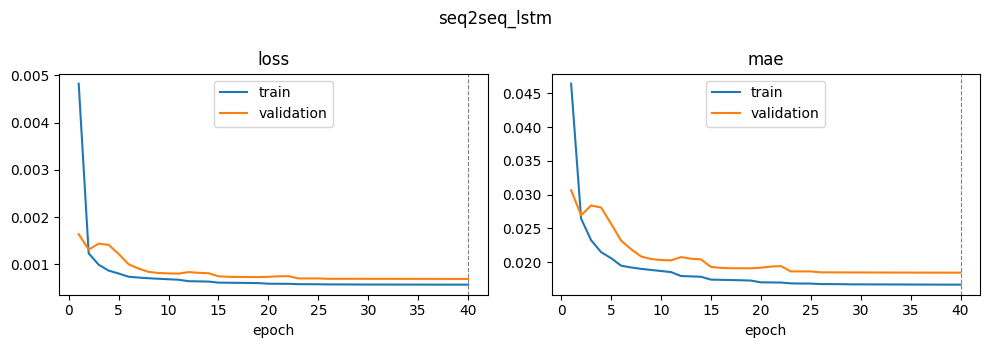

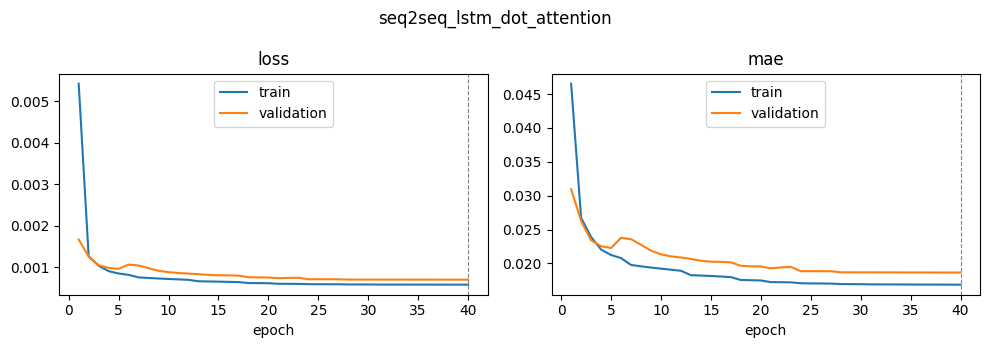

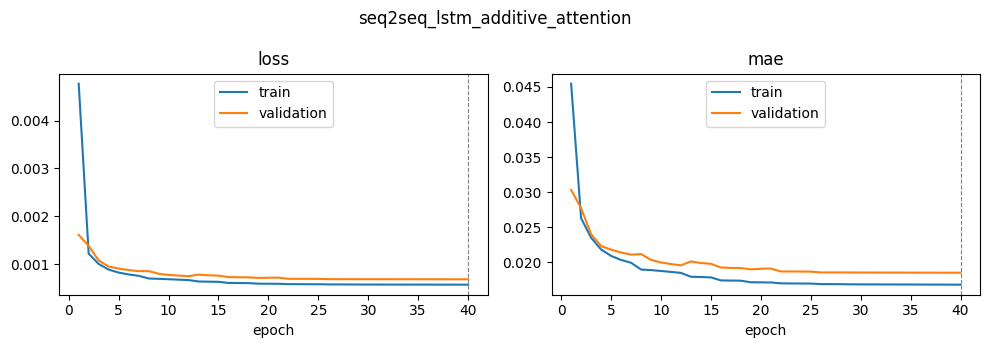

In [6]:
for run, history in histories.items():
    fig = plot_history(history, run, metric="mae")
    fig.savefig(FIG_DIR / f"{run}.png", dpi=150, bbox_inches="tight")
    plt.show()

All three models learn quickly: the validation loss drops sharply during the first 5 epochs and then slowly. `ReduceLROnPlateau` halves the learning rate several times, and it reaches the minimum of 1e-5 around epoch 29-31. After that the validation loss changes only in the sixth decimal (0.000694 at epoch 30 and 0.000692 at epoch 40 for the model without attention), so the runs had converged even though the best epoch is the last one. The training loss stays slightly below the validation loss (about 0.00057 against 0.00068-0.00070); this small gap does not indicate overfitting.

## 4. Validation results

The predictions are converted back to °C and evaluated for every forecast hour, as in notebook 01.

In [7]:
models = {run: load_trained(run) for run in RUNS}
y_val_c = inverse_target(y_val, sc, ti)

tables = {}
for run, model in models.items():
    pred = inverse_target(model.predict(X_val, verbose=0), sc, ti)
    tables[run] = multistep_metrics(y_val_c, pred)

# bảng tổng hợp: mỗi model một dòng, gộp cả 5 bước ("all steps")
overall = pd.DataFrame({run: t.loc["all steps"] for run, t in tables.items()}).T
overall["params"] = [m.count_params() for m in models.values()]
overall["best epoch"] = [int(histories[r]["val_loss"].idxmin()) + 1 for r in RUNS]
overall.round(4)

,R2,NSE,MAE,RMSE,params,best epoch
seq2seq_lstm,0.9752,0.9749,0.6235,0.8894,54081,40
seq2seq_lstm_dot_attention,0.9750,0.9748,0.6302,0.8921,56129,40
seq2seq_lstm_additive_attention,0.9755,0.9753,0.6264,0.8829,56193,40


In [8]:
# NSE và RMSE theo từng giờ dự báo
by_step = pd.concat({run: t.loc[[f"t+{h}" for h in range(1, HORIZON + 1)], ["NSE", "RMSE"]]
                     for run, t in tables.items()}, axis=1)
by_step.round(3)

seq2seq_lstm        seq2seq_lstm_dot_attention         \
             NSE   RMSE                        NSE   RMSE   
t+1        0.990  0.554                      0.990  0.562   
t+2        0.981  0.772                      0.981  0.773   
t+3        0.974  0.914                      0.974  0.912   
t+4        0.967  1.013                      0.967  1.014   
t+5        0.962  1.091                      0.962  1.098   

    seq2seq_lstm_additive_attention         
                                NSE   RMSE  
t+1                           0.990  0.561  
t+2                           0.981  0.768  
t+3                           0.974  0.904  
t+4                           0.968  1.000  
t+5                           0.963  1.084

- All three models are far better than the persistence baseline of notebook 01 on the validation set: RMSE over the five hours about 0.89 °C instead of 2.22 °C, NSE at t+5 about 0.96 instead of 0.69.
- The three models are almost identical. The additive attention model has the lowest RMSE (0.883 °C), the model without attention 0.889 °C and the dot attention model 0.892 °C. Differences of a few thousandths of a degree are too small to say that one model is better: with one run and one random seed per model they cannot be separated.
- For every model the error grows with the forecast horizon, from about 0.56 °C RMSE at t+1 to about 1.09 °C at t+5.

The additive attention model has the lowest validation RMSE, so it is used as the main model in notebook 03.